# Imports 

In [1]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from skopt import BayesSearchCV
from sklearn.metrics import confusion_matrix
import joblib
from sklvq import GLVQ
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier

random_state=42

-----

# Functions

In [2]:
def train_validation_test_split(
        X, y, validation_size=0.1,
        test_size=0.1, random_state=42):
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train, y_train,
        test_size=validation_size / (1 - test_size),
        random_state=random_state,
        stratify=y_train,
    )
    return X_train, X_valid, X_test, y_train, y_valid, y_test

In [3]:
from scipy import stats
def confidence_interval(data, confidence=0.95):
    mean = np.mean(data)
    n = len(data)
    std_err = np.std(data, ddof=1) / np.sqrt(n)
    t_value = stats.t.ppf((1 + confidence) / 2, n - 1)
    margin_of_error = t_value * std_err

    return f"{mean:.5f} ± {margin_of_error:.5f}"

In [4]:
def report_model_performance(model, X_train, X_valid, X_test, y_train, y_valid, y_test):
    
    accuracy_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Accuracy"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    precision_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Precision"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    recall_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_Recall"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    f1_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_F1"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    roc_best_param_cv = np.array([model.steps[-1][-1].cv_results_[f"split{i}_test_ROC-AUC"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]

    best_param = model.steps[-1][-1].best_params_
    print(f"Best parameters: {best_param}")
    print(f"Cross Validation accuracy Array: {accuracy_best_param_cv}")
    print(f"Validation accuracy: {confidence_interval(accuracy_best_param_cv)}")
    
    print(f"Cross Validation precision Array: {precision_best_param_cv}")
    print(f"Validation precision: {confidence_interval(precision_best_param_cv)}")
    
    print(f"Cross Validation recall Array: {recall_best_param_cv}")
    print(f"Validation recall: {confidence_interval(recall_best_param_cv)}")
    
    print(f"Cross Validation f1 Array: {f1_best_param_cv}")
    print(f"Validation f1: {confidence_interval(f1_best_param_cv)}")
    
    print(f"Cross Validation roc Array: {roc_best_param_cv}")
    print(f"Validation roc: {confidence_interval(roc_best_param_cv)}")
    
    print()
    y_train_pred = model.predict(X_train)
    y_valid_pred = model.predict(X_valid)
    y_test_pred = model.predict(X_test)
    
    y_train_proba = model.predict_proba(X_train)[:,1]
    y_valid_proba = model.predict_proba(X_valid)[:,1]
    y_test_proba = model.predict_proba(X_test)[:,1]
    print("===> Training performance")
    print(classification_report(y_train, y_train_pred, digits=5))
    print(f"Train ROC-AUC: {roc_auc_score(y_train, y_train_proba,):.3f}")
    print("===> Validation performance")
    print(classification_report(y_valid, y_valid_pred, digits=5))
    print(f"Validation ROC-AUC: {roc_auc_score(y_valid, y_valid_proba, ):.3f}")
    print("===> Test performance")
    print(classification_report(y_test, y_test_pred, digits=5))
    print(f"Test ROC-AUC: {roc_auc_score(y_test, y_test_proba,):.3f}")
    
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_train, y_train_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Train Confusion Matrix")
        plt.show()

    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_valid, y_valid_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Validation Confusion Matrix")
        plt.show()
        
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_test, y_test_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Test Confusion Matrix")
        plt.show()

In [5]:
def save_model(model, model_name):
    joblib.dump(model, f"{model_name}.joblib")

# Read Dataset

In [6]:
breast_cancer_wisconsin_diagnostic   = fetch_ucirepo(id=17)

X = breast_cancer_wisconsin_diagnostic .data.features
y = breast_cancer_wisconsin_diagnostic .data.targets

# Descritive statistics

In [7]:
X.describe()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [8]:
y.describe()

,Diagnosis
count,569
unique,2
top,B
freq,357


In [9]:
y["Diagnosis"].value_counts(normalize=True)

Diagnosis
B    0.627417
M    0.372583
Name: proportion, dtype: float64

<Axes: >

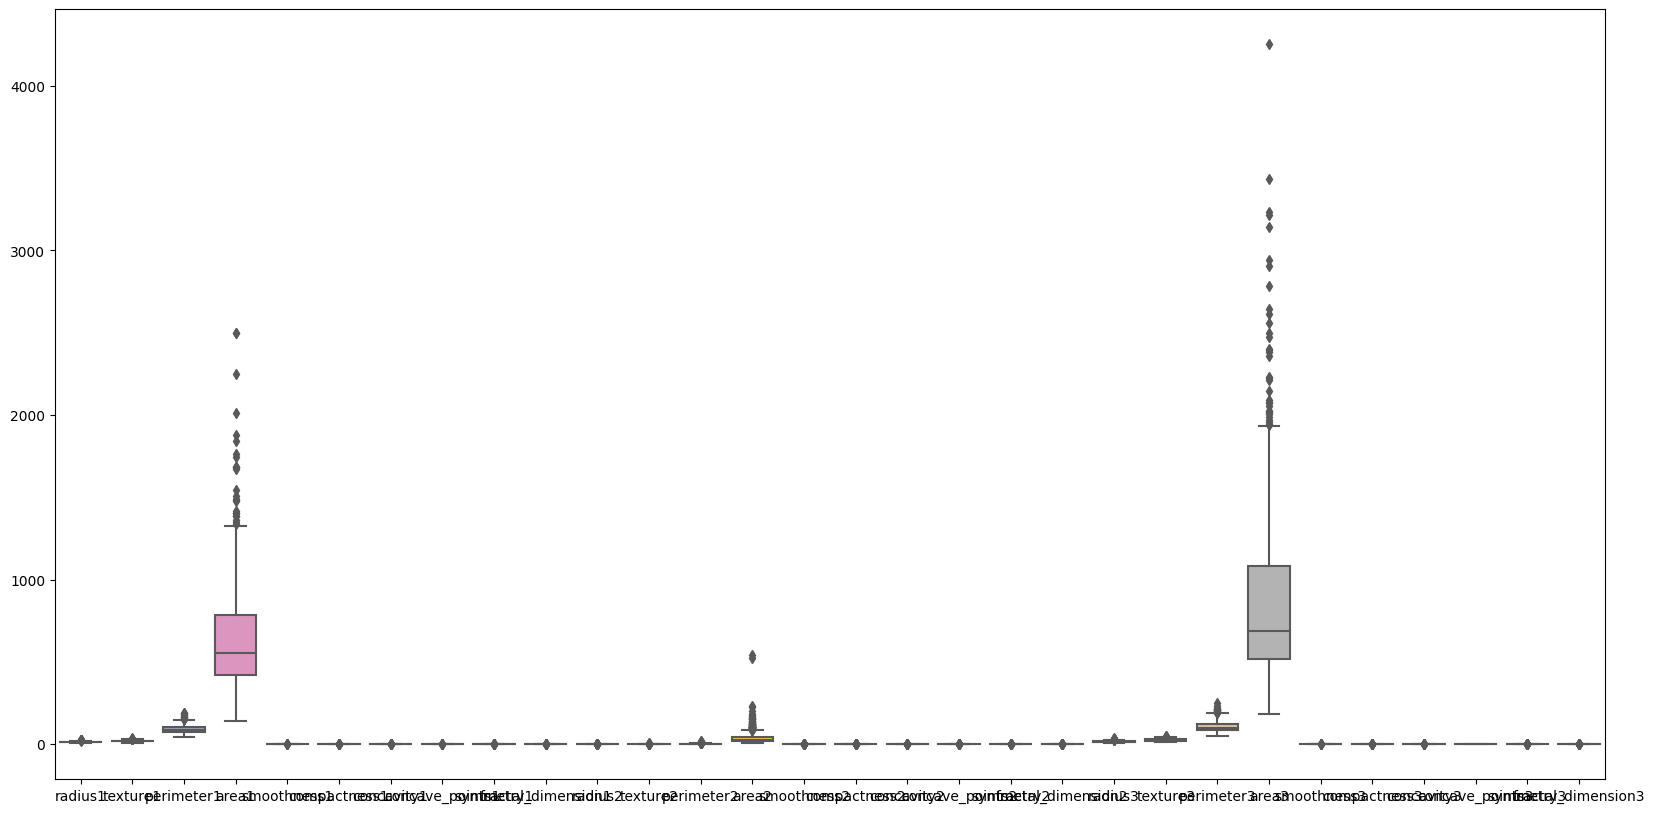

In [10]:
plt.figure(figsize=(20,10))
sns.boxplot(X, palette="Set2",)

## Split Dataset

In [11]:
X_train, X_valid, X_test, y_train, y_valid, y_test = train_validation_test_split(
    X, y, validation_size=0.15, test_size=0.15, random_state=random_state
)

In [12]:
X_train.shape, X_valid.shape, X_test.shape


((397, 30), (86, 30), (86, 30))

In [13]:
y_train.shape, y_valid.shape, y_test.shape

((397, 1), (86, 1), (86, 1))

In [14]:
y_train.value_counts(), y_valid.value_counts(), y_test.value_counts()

(Diagnosis
 B            249
 M            148
 Name: count, dtype: int64,
 Diagnosis
 B            54
 M            32
 Name: count, dtype: int64,
 Diagnosis
 B            54
 M            32
 Name: count, dtype: int64)

# Pre-processing

## Scaling the data

In [15]:
scaler_knn = MinMaxScaler()
scaler_lvq = MinMaxScaler()
scaler_dt = MinMaxScaler()
scaler_rf = MinMaxScaler()
scaler_ada = MinMaxScaler()
scaler_mlp = MinMaxScaler()

# Model

## KNN 

In [17]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
knn = KNeighborsClassifier()
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
knn_opt = BayesSearchCV(
    knn,
    {
        "n_neighbors": (1, 80),
        "weights": ["uniform", "distance"],
        "p": (1, 2, 3, 4, 5),
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_knn = Pipeline([("scaler", scaler_knn), ("knn", knn_opt)])

In [18]:
pipe_knn.fit(X_train, y_train["Diagnosis"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for eac

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('knn',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=KNeighborsClassifier(), n_iter=25,
                               n_jobs=-1, random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'n_neighbors': (1, 80),
                                              'p': (1, 2, 3, 4, 5),
                                              'weights': ['uniform',
                                                          'distance']},
                               verbose=1))])

Best parameters: OrderedDict([('n_neighbors', 6), ('p', 1), ('weights', 'distance')])
Cross Validation accuracy Array: [0.975  0.9625 0.95   0.95   0.975  0.9625 0.975  0.9625 0.9625 0.9875
 0.9625 0.975  0.95   0.9875 0.975  0.95   0.9375 0.9875 0.9625 0.9125
 0.9625 0.975  0.9375 0.9625 0.95   0.9875 0.9625 0.9625 0.9625 0.95
 0.9625 0.9375 0.9375 0.9375 0.975  0.9375 0.975  0.9625 0.975  0.975
 0.9625 1.     0.9625 0.975  0.9625 0.9625 0.9125 0.9625 0.9625 0.975 ]
Validation accuracy: 0.96175 ± 0.00504
Cross Validation precision Array: [0.98076923 0.96315078 0.94666667 0.9532967  0.98076923 0.97169811
 0.98076923 0.97169811 0.96315078 0.98387097 0.97169811 0.98076923
 0.96296296 0.98387097 0.98076923 0.96296296 0.95454545 0.99019608
 0.97169811 0.92545455 0.97169811 0.98076923 0.94374563 0.96315078
 0.94666667 0.99019608 0.97169811 0.96315078 0.95753785 0.96296296
 0.96315078 0.95454545 0.94374563 0.95454545 0.97333333 0.95454545
 0.98076923 0.97169811 0.97333333 0.97333333 0.963150

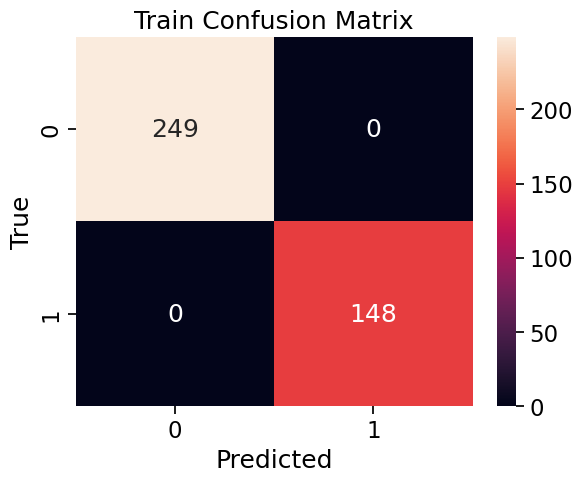

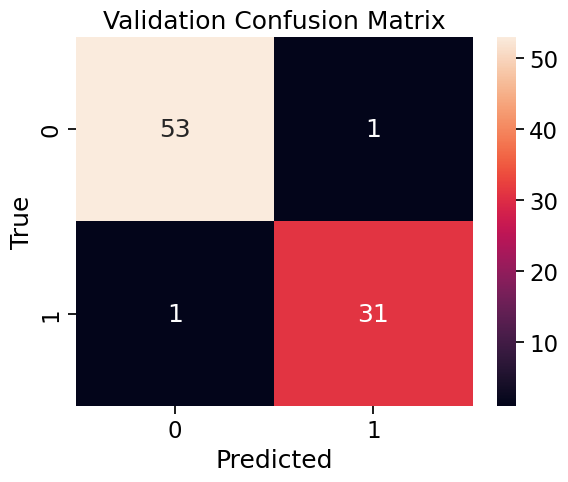

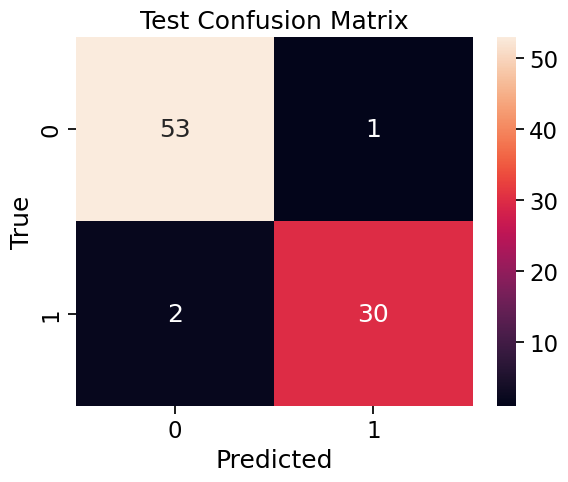

In [21]:
report_model_performance(pipe_knn, X_train, X_valid, X_test, y_train["Diagnosis"], y_valid["Diagnosis"], y_test["Diagnosis"])

In [22]:
save_model(pipe_knn, "knn")

## LVQ

In [16]:
from skopt.space import Integer, Categorical

cv = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=random_state)
lvq = GLVQ(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
lvq_opt = BayesSearchCV(
    lvq,
    {
        "prototype_n_per_class": (1,100),
        "distance_type": ["euclidean", "squared-euclidean"],
    },
    n_iter=4,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_lvq = Pipeline([("scaler", scaler_lvq), ("lvq", lvq_opt)])

In [17]:
pipe_lvq.fit(X_train, y_train["Diagnosis"])

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('lvq',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=5, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=GLVQ(random_state=42), n_iter=4,
                               n_jobs=-1, random_state=42, refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'distance_type': ['euclidean',
                                                                'squared-euclidean'],
                                              'prototype_n_per_class': (1,
                                                                        100)},
                               verbose=1))])

Best parameters: OrderedDict([('distance_type', 'squared-euclidean'), ('prototype_n_per_class', 18)])
Cross Validation accuracy Array: [0.975  0.925  0.95   0.9375 0.95  ]
Validation accuracy: 0.94750 ± 0.02302
Cross Validation precision Array: [0.98076923 0.92582418 0.9532967  0.94374563 0.96296296]
Validation precision: 0.95332 ± 0.02555
Cross Validation recall Array: [0.96666667 0.91333333 0.94       0.92333333 0.93333333]
Validation recall: 0.93533 ± 0.02511
Cross Validation f1 Array: [0.9729547  0.9188641  0.9459094  0.93186851 0.94505495]
Validation f1: 0.94293 ± 0.02496
Cross Validation roc Array: [0.99866667 0.98866667 0.976      0.98266667 0.98466667]
Validation roc: 0.98613 ± 0.01040

===> Training performance
              precision    recall  f1-score   support

           B    0.93585   0.99598   0.96498       249
           M    0.99242   0.88514   0.93571       148

    accuracy                        0.95466       397
   macro avg    0.96414   0.94056   0.95035       39

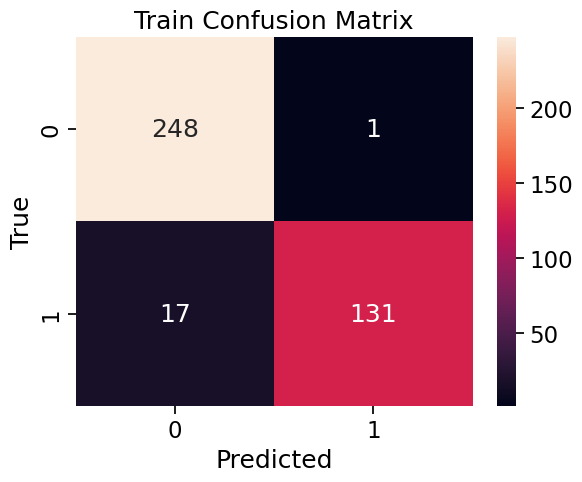

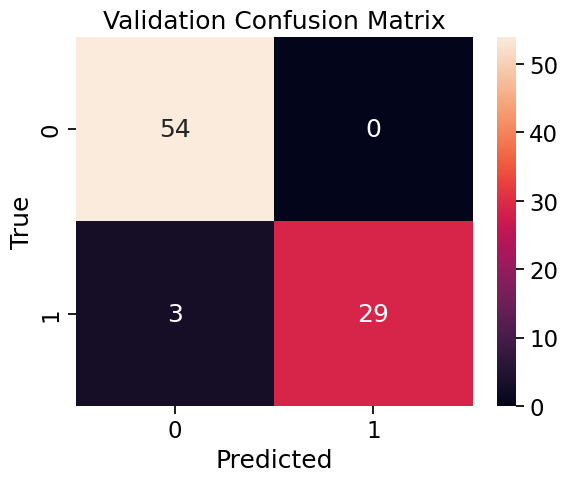

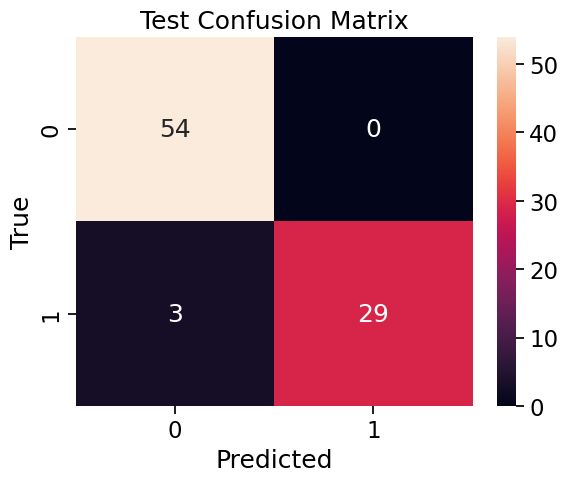

In [18]:
report_model_performance(pipe_lvq, X_train, X_valid, X_test, y_train["Diagnosis"], y_valid["Diagnosis"], y_test["Diagnosis"])

In [19]:
save_model(pipe_lvq, "lvq")

## Decision Tree 

In [25]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
dt = DecisionTreeClassifier(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
dt_opt = BayesSearchCV(
    dt,
    {
        "criterion": ["gini", "entropy"],
        "splitter": ["best", "random"],
        "max_depth": (1, 100),
        "min_samples_split": (2, 100),
        "min_samples_leaf": (1, 100),
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_dt = Pipeline([("scaler", scaler_dt), ("dt", dt_opt)])

In [26]:
pipe_dt.fit(X_train, y_train["Diagnosis"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for eac

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('dt',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=DecisionTreeClassifier(random_state=42),
                               n_iter=25, n_jobs=-1, random_state=42,
                               refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'criterion': ['gini', 'entropy'],
                                              'max_depth': (1, 100),
                                              'min_samples_leaf': (1, 100),
                                              'min_samples_split': (2, 100),
                                              'splitter': ['best', 'random']},
                               verbose=1))])

In [27]:
save_model(pipe_dt, "dt")

Best parameters: OrderedDict([('criterion', 'gini'), ('max_depth', 92), ('min_samples_leaf', 11), ('min_samples_split', 44), ('splitter', 'best')])
Cross Validation accuracy Array: [0.9125 0.95   0.9375 0.95   0.9125 0.9125 0.925  0.8625 0.8875 0.95
 0.925  0.975  0.9125 0.9    0.925  0.9375 0.925  0.9375 0.8625 0.8875
 0.85   0.925  0.95   0.9    0.8625 0.9    0.925  0.875  0.925  0.8625
 0.9125 0.925  0.9125 0.925  0.8875 0.9    0.925  0.925  0.9375 0.95
 0.9125 0.9625 0.925  0.95   0.95   0.875  0.9125 0.925  0.8875 0.9375]
Validation accuracy: 0.91600 ± 0.00818
Cross Validation precision Array: [0.9031746  0.94666667 0.92875564 0.9532967  0.90906018 0.90296583
 0.92       0.85496957 0.87853851 0.94666667 0.92       0.98076923
 0.90906018 0.89141414 0.92582418 0.94374563 0.93447293 0.93610548
 0.89144471 0.90808543 0.85714286 0.92       0.9532967  0.89002558
 0.87757437 0.89002558 0.92582418 0.86445013 0.92       0.85496957
 0.90906018 0.93447293 0.90906018 0.93447293 0.88201487 0.8

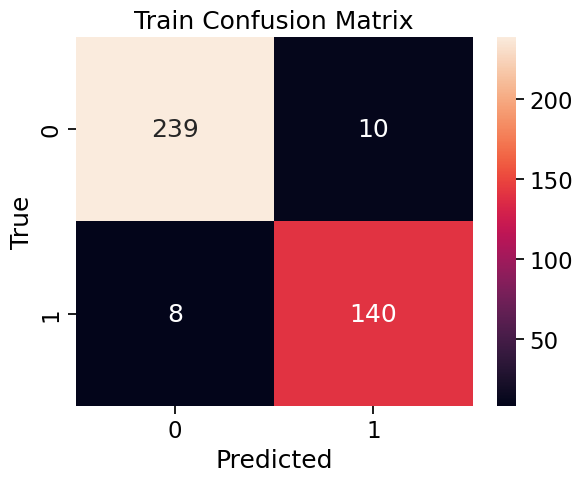

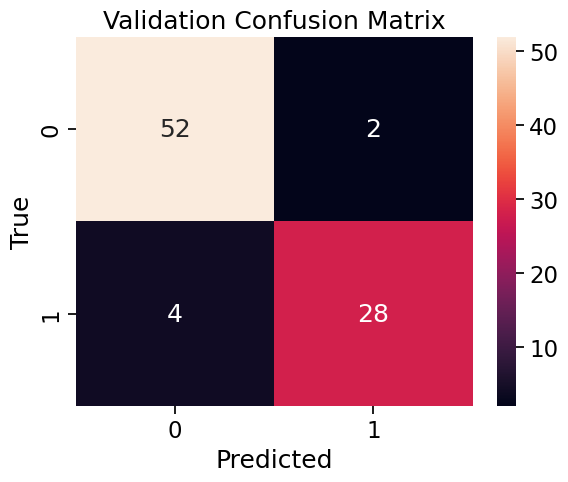

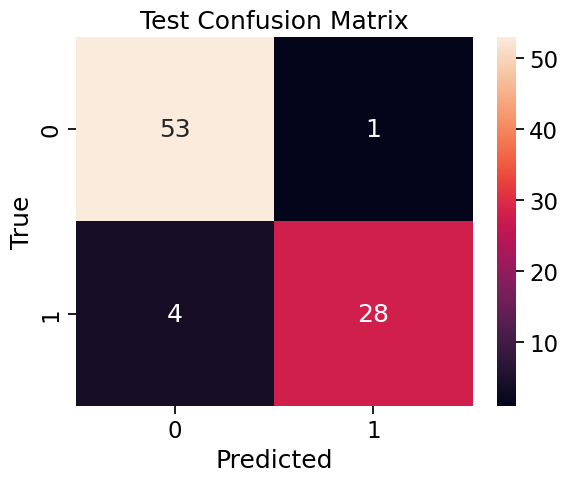

In [28]:
report_model_performance(pipe_dt, X_train, X_valid, X_test, y_train["Diagnosis"], y_valid["Diagnosis"], y_test["Diagnosis"])

## Random Forest

In [29]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
rf = RandomForestClassifier(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
rf_opt = BayesSearchCV(
    rf,
    {
        "n_estimators": (1, 1000),
        "criterion": ["gini", "entropy"],
        "max_depth": (1, 100),
        "min_samples_split": (2, 100),
        "min_samples_leaf": (1, 100),
        "max_features": Categorical([None, "sqrt", "log2"]),
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_rf = Pipeline([("scaler", scaler_rf), ("rfr", rf_opt)])

In [30]:
pipe_rf.fit(X_train, y_train["Diagnosis"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for eac

c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point ['entropy', 100, 'log2', 1, 2, 1000] before, using random point ['gini', 72, 'log2', 78, 87, 418]
  warnings.warn(


Fitting 50 folds for each of 1 candidates, totalling 50 fits


c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point ['entropy', 100, 'log2', 1, 2, 1000] before, using random point ['entropy', 23, None, 39, 61, 191]
  warnings.warn(


Fitting 50 folds for each of 1 candidates, totalling 50 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('rfr',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=RandomForestClassifier(random_state=42),
                               n_iter=25, n_jobs=-1, random_state=42,
                               refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'criterion': ['gini', 'entropy'],
                                              'max_depth': (1, 100),
                                              'max_features': Categorical(categories=(None, 'sqrt', 'log2'), prior=None),
                                              'min_samples_leaf': (1, 100),
                                              'min_samples_split': (2, 100),
                                              'n_estimators': (1, 1000)},
                               verbose=1))])

In [31]:
save_model(pipe_rf, "rf")

Best parameters: OrderedDict([('criterion', 'entropy'), ('max_depth', 100), ('max_features', 'log2'), ('min_samples_leaf', 1), ('min_samples_split', 2), ('n_estimators', 223)])
Cross Validation accuracy Array: [0.975  0.975  0.9625 0.9375 0.9625 0.975  0.975  0.9125 0.9375 0.975
 0.95   0.9875 0.95   0.9625 0.9875 0.9625 0.9875 0.95   0.9375 0.9
 0.95   0.9625 0.95   0.95   0.9125 0.9625 0.95   0.9375 0.975  0.9375
 0.975  0.95   0.95   0.95   0.95   0.9125 0.975  0.95   0.975  0.975
 0.925  0.9875 0.9375 0.975  0.975  0.925  0.9375 0.9625 0.975  0.975 ]
Validation accuracy: 0.95575 ± 0.00614
Cross Validation precision Array: [0.97333333 0.97333333 0.95753785 0.93610548 0.96315078 0.98076923
 0.98076923 0.90906018 0.93120474 0.97333333 0.94666667 0.99019608
 0.9532967  0.95454545 0.99019608 0.97169811 0.99019608 0.94666667
 0.94374563 0.90598291 0.9532967  0.96315078 0.9532967  0.94270833
 0.90906018 0.95753785 0.9532967  0.93120474 0.97333333 0.94374563
 0.96875    0.96296296 0.953296

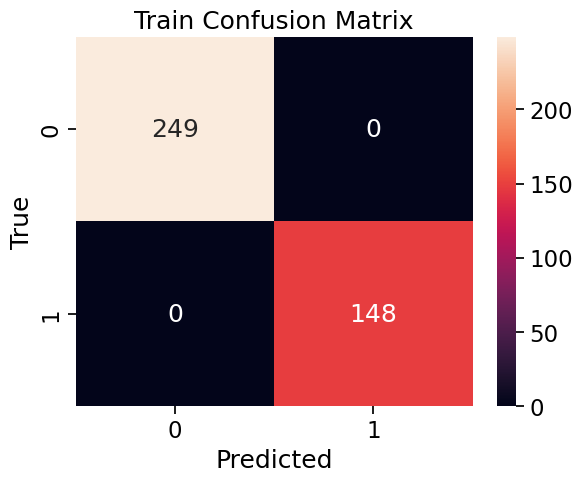

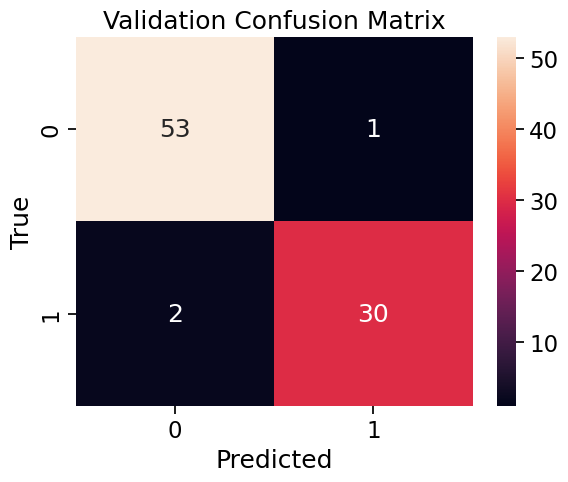

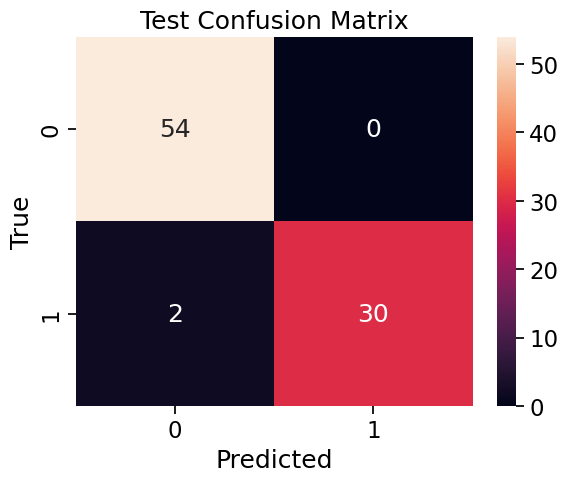

In [32]:
report_model_performance(pipe_rf, X_train, X_valid, X_test, y_train["Diagnosis"], y_valid["Diagnosis"], y_test["Diagnosis"])

## AdaBoost

In [33]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
ada = AdaBoostClassifier(random_state=random_state)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
ada_opt = BayesSearchCV(
    ada,
    {
        "n_estimators": (1, 1000),
        "learning_rate": (0.01, 1),
        "algorithm": ["SAMME", "SAMME.R"],
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_opt = Pipeline([("scaler", scaler_ada), ("ada", ada_opt)])

In [34]:
pipe_opt.fit(X_train, y_train["Diagnosis"])

Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for each of 1 candidates, totalling 50 fits
Fitting 50 folds for eac

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('ada',
                 BayesSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
                               estimator=AdaBoostClassifier(random_state=42),
                               n_iter=25, n_jobs=-1, random_state=42,
                               refit='Accuracy',
                               scoring={'Accuracy': 'accuracy',
                                        'F1': 'f1_macro',
                                        'Precision': 'precision_macro',
                                        'ROC-AUC': 'roc_auc_ovr',
                                        'Recall': 'recall_macro'},
                               search_spaces={'algorithm': ['SAMME', 'SAMME.R'],
                                              'learning_rate': (0.01, 1),
                                              'n_estimators': (1, 1000)},
                               verbose=1))])

In [35]:
save_model(pipe_opt, "ada")

Best parameters: OrderedDict([('algorithm', 'SAMME.R'), ('learning_rate', 1.0), ('n_estimators', 1000)])
Cross Validation accuracy Array: [0.9625 0.95   0.9625 0.975  0.9625 0.9875 0.9875 0.95   0.9625 0.975
 0.9625 0.975  0.975  0.975  0.95   0.95   0.975  0.975  0.95   0.9125
 0.9625 0.925  0.925  0.9625 0.925  0.975  0.9625 0.9625 0.975  0.95
 0.9875 0.95   0.9375 0.925  0.9625 0.95   0.9875 0.95   0.9875 0.975
 0.975  1.     0.95   0.9875 1.     0.95   0.9375 0.975  0.95   0.9375]
Validation accuracy: 0.96150 ± 0.00578
Cross Validation precision Array: [0.96315078 0.9532967  0.95753785 0.97333333 0.97169811 0.99019608
 0.99019608 0.96296296 0.97169811 0.97333333 0.96315078 0.98076923
 0.97333333 0.96875    0.9532967  0.9532967  0.98076923 0.96875
 0.9532967  0.90906018 0.97169811 0.92       0.93447293 0.96315078
 0.92       0.97333333 0.95753785 0.96315078 0.97333333 0.9532967
 0.98387097 0.9532967  0.93610548 0.94642857 0.95753785 0.9532967
 0.99019608 0.94666667 0.99019608 0.9733

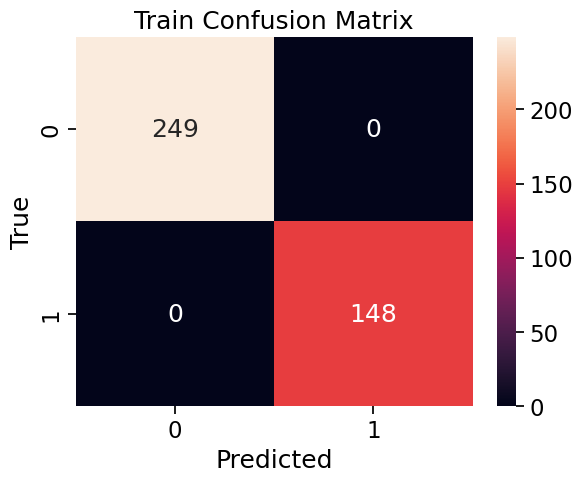

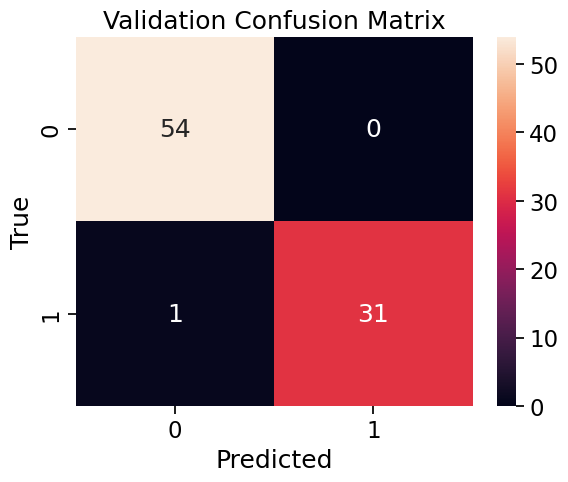

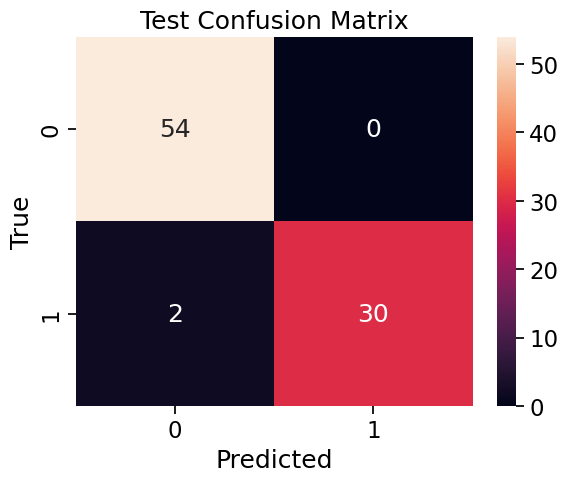

In [36]:
report_model_performance(pipe_opt, X_train, X_valid, X_test, y_train["Diagnosis"], y_valid["Diagnosis"], y_test["Diagnosis"])

## MLP

In [41]:
cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
mlp = MLPClassifier(random_state=random_state, max_iter=1000)
scoring = {
    "Accuracy": "accuracy", "ROC-AUC": "roc_auc_ovr",
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}
mlp_opt = RandomizedSearchCV(
    mlp,
    {
        "hidden_layer_sizes": [(5,), (10,), (5, 10), (10, 5), (10, 10)],
        "activation": ["identity", "logistic", "tanh", "relu"],
        "solver": ["lbfgs", "sgd", "adam"],
        "alpha": np.arange(0, 100),
        "learning_rate": ["constant", "invscaling", "adaptive"],
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=1,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_mlp = Pipeline([("scaler", scaler_mlp), ("mlp", mlp_opt)])

In [42]:
pipe_mlp.fit(X_train, y_train["Diagnosis"])

Fitting 5 folds for each of 4 candidates, totalling 20 fits


Pipeline(steps=[('scaler', MinMaxScaler()),
                ('mlp',
                 RandomizedSearchCV(cv=StratifiedShuffleSplit(n_splits=5, random_state=42, test_size=0.2,
            train_size=None),
                                    estimator=MLPClassifier(max_iter=1000,
                                                            random_state=42),
                                    n_iter=4, n_jobs=-1,
                                    param_distributions={'activation': ['identity',
                                                                        'logistic',
                                                                        'tanh',
                                                                        'relu'],
                                                         'alpha': array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15...
       85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]),
                                                         'hidden_layer_sizes': [(5,),
                                                                                (10,),
                                                                                (5,
                                                                                 10),
                                                                                (10,
                                                                                 5),
                                                                                (10,
                                                                                 10)],
                                                         'learning_rate': ['constant',
                                                                           'invscaling',
                                                                           'adaptive'],
                                                         'solver': ['lbfgs',
                                                                    'sgd',
                                                                    'adam']},
                                    random_state=42, refit='Accuracy',
                                    scoring={'Accuracy': 'accuracy',
                                             'F1': 'f1_macro',
                                             'Precision': 'precision_macro',
                                             'ROC-AUC': 'roc_auc_ovr',
                                             'Recall': 'recall_macro'},
                                    verbose=1))])

Best parameters: {'solver': 'lbfgs', 'learning_rate': 'invscaling', 'hidden_layer_sizes': (10, 10), 'alpha': 65, 'activation': 'tanh'}
Cross Validation accuracy Array: [0.54505495 0.52087912 0.51428571 0.53516484 0.53296703]
Validation accuracy: 0.52967 ± 0.01510
Cross Validation precision Array: [0.30206161 0.24521884 0.29275202 0.15534456 0.19244124]
Validation precision: 0.23756 ± 0.07868
Cross Validation recall Array: [0.20171245 0.19378551 0.19010365 0.1977697  0.1963389 ]
Validation recall: 0.19594 ± 0.00540
Cross Validation f1 Array: [0.17830254 0.17405444 0.16800465 0.17322397 0.17407525]
Validation f1: 0.17353 ± 0.00456
Cross Validation roc Array: [0.6196035  0.65825955 0.64480121 0.58999812 0.67645022]
Validation roc: 0.63782 ± 0.04200

===> Training performance
              precision    recall  f1-score   support

           3    0.00000   0.00000   0.00000        21
           4    0.00000   0.00000   0.00000       152
           5    0.57375   0.61364   0.59302      1496


c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\Marcos\OneDrive\Desktop\Meus Projetos\AM-msc\Projetos-AM\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

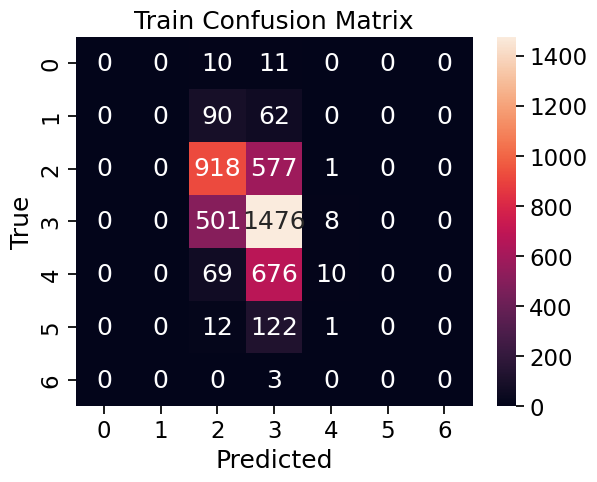

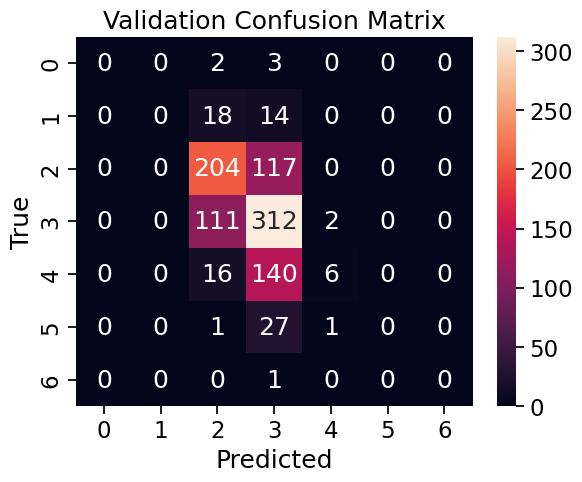

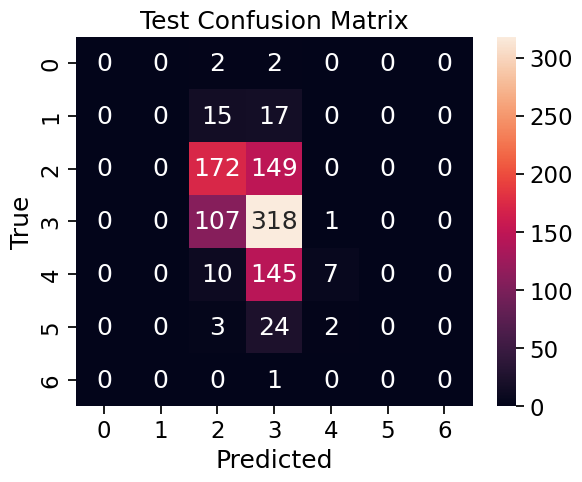

In [150]:
report_model_performance(pipe_mlp, X_train, X_valid, X_test, y_train["Diagnosis"], y_valid["Diagnosis"], y_test["Diagnosis"])

In [151]:
save_model(pipe_mlp, "mlp")

## ELM